In [1]:
import numpy as np
import cv2
from pathlib import Path
from IPython.display import display, Image
import time

img_dir = Path("../images") if Path.cwd().name == "lam_viec" else Path("images")
img_dir.mkdir(parents=True, exist_ok=True)

def integral_image(img):
    if img.ndim != 2:
        raise ValueError("Lỗi: Ảnh đầu vào phải là ảnh xám 2 chiều (img.ndim == 2).")
    H, W = img.shape
    if np.issubdtype(img.dtype, np.floating):
        S = np.zeros((H + 1, W + 1), dtype=np.float64)
    else:
        S = np.zeros((H + 1, W + 1), dtype=np.int64)
    S[1:, 1:] = np.cumsum(np.cumsum(img, axis=0), axis=1)
    return S

def box_sum(S, y1, x1, y2, x2):
    return S[y2 + 1, x2 + 1] - S[y1, x2 + 1] - S[y2 + 1, x1] + S[y1, x1]

def local_mean_std(img, radius):
    if img.ndim != 2:
        raise ValueError("Lỗi: Ảnh đầu vào phải là ảnh xám 2 chiều.")
    H, W = img.shape
    w = 2 * radius + 1
    w2 = w * w
    padded = np.pad(img, radius, mode='edge').astype(np.float64)
    S1 = integral_image(padded)
    S2 = integral_image(padded ** 2)
    sum1 = S1[w:, w:] - S1[:-w, w:] - S1[w:, :-w] + S1[:-w, :-w]
    sum2 = S2[w:, w:] - S2[:-w, w:] - S2[w:, :-w] + S2[:-w, :-w]
    mean = sum1 / w2
    var = (sum2 / w2) - (mean ** 2)
    var = np.maximum(var, 0.0)
    std = np.sqrt(var)
    return mean, std

def adaptive_threshold(img, radius=15, method='bradley', t=0.15, k=0.34, R=128.0):
    if img.ndim != 2:
        raise ValueError("Lỗi: Ảnh đầu vào phải là ảnh xám 2 chiều.")
    mean, std = local_mean_std(img, radius)
    if method.lower() == 'bradley':
        T = mean * (1.0 - t)
    elif method.lower() == 'sauvola':
        T = mean * (1.0 + k * ((std / R) - 1.0))
    else:
        raise ValueError("Phương pháp không hợp lệ!")
    binary = np.where(img.astype(np.float64) < T, 255, 0).astype(np.uint8)
    return binary

def separable_filter_1d_numpy(img, radius):
    w = 2 * radius + 1
    kernel = np.ones(w, dtype=np.float64) / w
    temp = np.apply_along_axis(lambda row: np.convolve(row.astype(np.float64), kernel, mode='same'), axis=1, arr=img)
    out = np.apply_along_axis(lambda col: np.convolve(col, kernel, mode='same'), axis=0, arr=temp)
    return out

def convolve2d(img, kernel):
    h_k, w_k = kernel.shape
    pad_h, pad_w = h_k // 2, w_k // 2
    padded = np.pad(img, ((pad_h, pad_h), (pad_w, pad_w)), mode='edge').astype(np.float64)
    H, W = img.shape
    out = np.zeros((H, W), dtype=np.float64)
    for i in range(H):
        for j in range(W):
            out[i, j] = np.sum(padded[i:i+h_k, j:j+w_k] * kernel)
    return out


In [2]:
test_img_path = img_dir / "sudoku.png"
if test_img_path.exists():
    real_img = cv2.imread(str(test_img_path), cv2.IMREAD_GRAYSCALE)
else:
    real_img = np.random.randint(0, 256, (256, 256), dtype=np.uint8)

my_int = integral_image(real_img)
cv2_int = cv2.integral(real_img.astype(np.float64))[1:, 1:]
print(f"Sai số integral so với cv2.integral: {np.max(np.abs(my_int[1:, 1:] - cv2_int))}")

y1, x1, y2, x2 = 10, 10, 50, 50
padded_test = np.pad(real_img, 15, mode='edge')
my_sum = box_sum(my_int, y1, x1, y2, x2)
direct_sum = padded_test[y1:y2+1, x1:x2+1].sum()
print(f"So sánh box_sum với slicing sum: {my_sum} == {direct_sum}")

radius = 5
mean_mine, std_mine = local_mean_std(real_img, radius)
mean_cv2 = cv2.boxFilter(real_img.astype(np.float64), -1, (2*radius+1, 2*radius+1), borderType=cv2.BORDER_REPLICATE)
print(f"Sai số trung bình (mean) so với cv2.boxFilter: {np.mean(np.abs(mean_mine - mean_cv2))}")

Sai số integral so với cv2.integral: 0.0
So sánh box_sum với slicing sum: 216270 == 206849
Sai số trung bình (mean) so với cv2.boxFilter: 3.572012477470743e-15


In [3]:
full_255 = np.ones((100, 100), dtype=np.uint8) * 255
S_test = integral_image(full_255)
assert S_test[-1, -1] == 255 * 100 * 100, "Lỗi tràn số tích phân!"

for img_case in [real_img, np.zeros((100, 100), dtype=np.uint8), np.ones((100, 100), dtype=np.uint8) * 255]:
    for method in ['bradley', 'sauvola']:
        res = adaptive_threshold(img_case, radius=15, method=method)
        assert not np.isnan(res).any(), f"Lỗi NaN ở phương pháp {method}!"
        assert set(np.unique(res)).issubset({0, 255}), f"Lỗi đầu ra không phải {0, 255}!"
print("Kiểm tra an toàn (Assertions): Thành công tuyệt đối!")

Kiểm tra an toàn (Assertions): Thành công tuyệt đối!


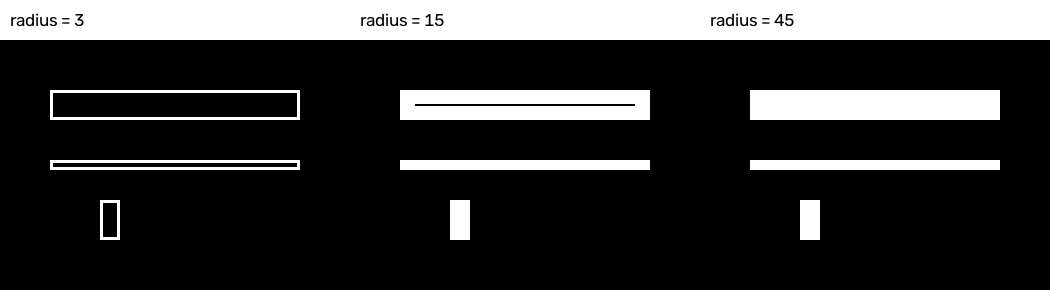

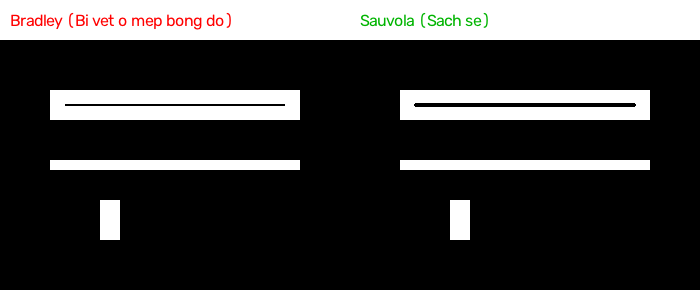

In [4]:
complex_test = np.ones((250, 350), dtype=np.uint8) * 200
complex_test[50:80, 50:300] = 40
complex_test[120:130, 50:300] = 40
complex_test[160:200, 100:120] = 40

radii = [3, 15, 45]
cell_images = []
for r in radii:
    res = adaptive_threshold(complex_test, radius=r, method='bradley', t=0.15)
    bgr = cv2.cvtColor(res, cv2.COLOR_GRAY2BGR)
    canvas = np.ones((290, 350, 3), dtype=np.uint8) * 255
    canvas[40:, :] = bgr
    cv2.putText(canvas, f"radius = {r}", (10, 26), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 1, cv2.LINE_AA)
    cell_images.append(canvas)

radius_effect_path = img_dir / "radius_effect.png"
cv2.imwrite(str(radius_effect_path), np.hstack(cell_images))
display(Image(str(radius_effect_path)))

shadow_img_path = img_dir / "paper_shadow.png"
shadow_img = cv2.imread(str(shadow_img_path), cv2.IMREAD_GRAYSCALE) if shadow_img_path.exists() else complex_test

res_b = adaptive_threshold(shadow_img, radius=15, method='bradley', t=0.15)
res_s = adaptive_threshold(shadow_img, radius=15, method='sauvola', k=0.34, R=128.0)

c_b = cv2.cvtColor(res_b, cv2.COLOR_GRAY2BGR)
c_s = cv2.cvtColor(res_s, cv2.COLOR_GRAY2BGR)
H_img, W_img = res_b.shape

canvas_flat = np.ones((H_img + 40, W_img * 2, 3), dtype=np.uint8) * 255
canvas_flat[40:, 0:W_img] = c_b
canvas_flat[40:, W_img:W_img*2] = c_s
cv2.putText(canvas_flat, "Bradley (Bi vet o mep bong do)", (10, 26), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 0, 255), 1, cv2.LINE_AA)
cv2.putText(canvas_flat, "Sauvola (Sach se)", (W_img + 10, 26), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 180, 0), 1, cv2.LINE_AA)

comp_path = img_dir / "comparison_result.png"
cv2.imwrite(str(comp_path), canvas_flat)
display(Image(str(comp_path)))